# Image Processing Practical File 2 — 10 Programs

**Topics:** Edge detection, compression, feature extraction, segmentation, morphology, contours, enhancement, and denoising.

## Program 1 — Compare Sobel, Laplacian, and Canny edge detection

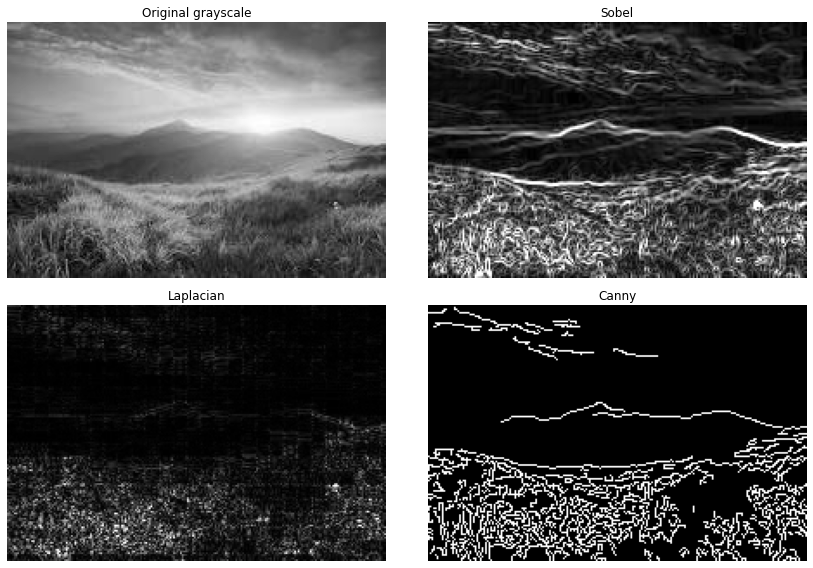

In [1]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread("natural_scene.jpg", cv2.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError("Add a natural image named natural_scene.jpg or update the filename.")

sobel_x = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
sobel = cv2.convertScaleAbs(cv2.magnitude(sobel_x, sobel_y))
laplacian = cv2.convertScaleAbs(cv2.Laplacian(img, cv2.CV_64F))
canny = cv2.Canny(img, 100, 200)

titles = ["Original grayscale", "Sobel", "Laplacian", "Canny"]
images = [img, sobel, laplacian, canny]
plt.figure(figsize=(12, 8))
for i, (title, result) in enumerate(zip(titles, images), 1):
    plt.subplot(2, 2, i)
    plt.imshow(result, cmap="gray")
    plt.title(title)
    plt.axis("off")
plt.tight_layout()
plt.show()

**Observation guide:** Sobel estimates directional intensity changes; Laplacian responds to second-order changes and may amplify noise; Canny uses smoothing, gradients, and edge linking to produce comparatively thin edges. Describe which result best preserves meaningful boundaries in your chosen image.

## Program 2 — Test edge detectors on Gaussian and salt-and-pepper noise

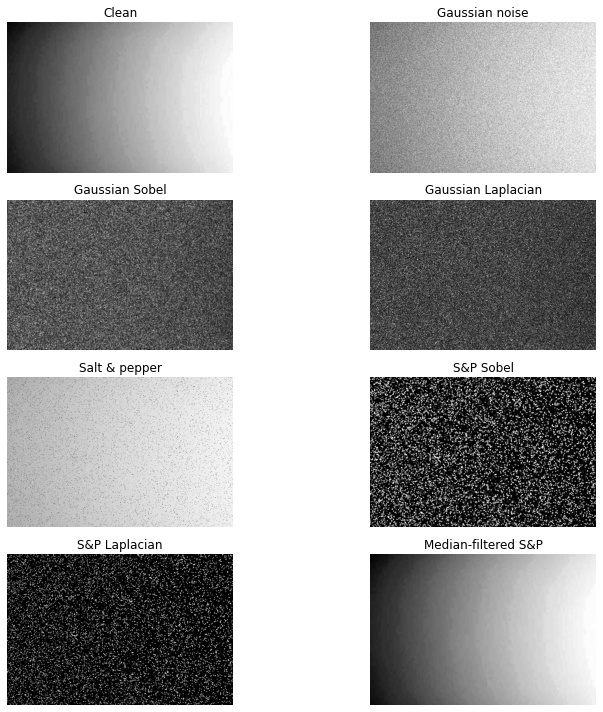

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
img = cv2.imread("clean_gray.jpg", cv2.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError("Add a grayscale image named clean_gray.jpg.")

# Gaussian noise
gaussian_noise = rng.normal(0, 20, img.shape)
gaussian_img = np.clip(img.astype(np.float32) + gaussian_noise, 0, 255).astype(np.uint8)

# Salt-and-pepper noise
sp_img = img.copy()
mask = rng.random(img.shape)
sp_img[mask < 0.02] = 0
sp_img[mask > 0.98] = 255

def edge_pair(gray):
    sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    sobel = cv2.convertScaleAbs(cv2.magnitude(sobel_x, sobel_y))
    lap = cv2.convertScaleAbs(cv2.Laplacian(gray, cv2.CV_64F))
    return sobel, lap

gauss_sobel, gauss_lap = edge_pair(gaussian_img)
sp_sobel, sp_lap = edge_pair(sp_img)
gauss_median = cv2.medianBlur(gaussian_img, 3)
sp_median = cv2.medianBlur(sp_img, 3)

items = [
    ("Clean", img), ("Gaussian noise", gaussian_img), ("Gaussian Sobel", gauss_sobel),
    ("Gaussian Laplacian", gauss_lap), ("Salt & pepper", sp_img), ("S&P Sobel", sp_sobel),
    ("S&P Laplacian", sp_lap), ("Median-filtered S&P", sp_median)
]
plt.figure(figsize=(12, 10))
for i, (title, arr) in enumerate(items, 1):
    plt.subplot(4, 2, i)
    plt.imshow(arr, cmap="gray")
    plt.title(title)
    plt.axis("off")
plt.tight_layout()
plt.show()

**Observation guide:** Compare how many false edges noise creates. Derivative operators, especially the Laplacian, are often noise-sensitive. Median filtering is useful for salt-and-pepper noise; Gaussian smoothing is often tried before gradient-based edge detection.

## Program 3 — Compare Run-Length Encoding (RLE) and Huffman coding

In [4]:
import cv2
from collections import Counter
import heapq
import itertools

img = cv2.imread("smooth_gray.png", cv2.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError("Add a grayscale image named smooth_gray.png.")

# RLE of the flattened pixel sequence: each run stores (value, count).
pixels = img.ravel().tolist()
runs = []
for value in pixels:
    if runs and runs[-1][0] == value:
        runs[-1][1] += 1
    else:
        runs.append([value, 1])

# Estimate a simple fixed storage cost: 8 bits for value + 32 bits for run length.
rle_bits = len(runs) * (8 + 32)
original_bits = len(pixels) * 8

# Build Huffman code lengths from symbol frequencies.
freq = Counter(pixels)
counter = itertools.count()
heap = [(count, next(counter, None), {symbol: ""}) for symbol, count in []]  # unused placeholder
heap = [(count, next(counter), symbol) for symbol, count in freq.items()]
heapq.heapify(heap)
if len(heap) == 1:
    huffman_bits = len(pixels)  # one-symbol special case, approximate 1 bit per pixel
else:
    while len(heap) > 1:
        f1, _, left = heapq.heappop(heap)
        f2, _, right = heapq.heappop(heap)
        heapq.heappush(heap, (f1 + f2, next(counter), (left, right)))
    root = heap[0][2]
    lengths = {}
    def walk(node, depth):
        if isinstance(node, int):
            lengths[node] = max(depth, 1)
        else:
            walk(node[0], depth + 1)
            walk(node[1], depth + 1)
    walk(root, 0)
    huffman_bits = sum(freq[symbol] * lengths[symbol] for symbol in freq)

def reduction(before, after):
    return (before - after) / before * 100 if before else 0

print("Original raw pixel bits:", original_bits)
print("RLE estimated bits (8-bit value + 32-bit run length):", rle_bits)
print("Huffman payload bits (tree/header overhead excluded):", huffman_bits)
print(f"RLE reduction: {reduction(original_bits, rle_bits):.2f}%")
print(f"Huffman payload reduction: {reduction(original_bits, huffman_bits):.2f}%")
print("Note: estimates exclude file headers; Huffman excludes the codebook/header, so it is not a complete file-size comparison.")

Original raw pixel bits: 2451648
RLE estimated bits (8-bit value + 32-bit run length): 454160
Huffman payload bits (tree/header overhead excluded): 1363096
RLE reduction: 81.48%
Huffman payload reduction: 44.40%
Note: estimates exclude file headers; Huffman excludes the codebook/header, so it is not a complete file-size comparison.


**Explanation:** RLE is effective when adjacent pixels repeat in long runs. Huffman coding assigns shorter codes to frequent pixel values. These are educational estimates, not complete compressed image files: RLE's run-length storage assumption is stated, and Huffman codebook/header overhead is excluded.

## Program 4 — JPEG-style 8×8 DCT quantisation and PSNR/SSIM comparison

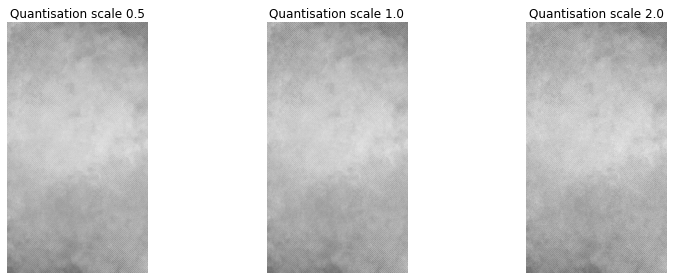

Scale 0.5: PSNR=43.00 dB, SSIM=0.9945
Scale 1.0: PSNR=31.46 dB, SSIM=0.9203
Scale 2.0: PSNR=28.96 dB, SSIM=0.8558


In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as ssim

img = cv2.imread("texture_gray.jpg", cv2.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError("Add a grayscale image named texture_gray.jpg.")

# Standard illustrative JPEG luminance quantisation matrix.
Q = np.array([
[16,11,10,16,24,40,51,61],
[12,12,14,19,26,58,60,55],
[14,13,16,24,40,57,69,56],
[14,17,22,29,51,87,80,62],
[18,22,37,56,68,109,103,77],
[24,35,55,64,81,104,113,92],
[49,64,78,87,103,121,120,101],
[72,92,95,98,112,100,103,99]
], dtype=np.float32)

def jpeg_style(gray, scale):
    h, w = gray.shape
    pad_h, pad_w = (-h) % 8, (-w) % 8
    padded = cv2.copyMakeBorder(gray, 0, pad_h, 0, pad_w, cv2.BORDER_REFLECT)
    padded = padded.astype(np.float32) - 128
    out = np.zeros_like(padded)
    for y in range(0, padded.shape[0], 8):
        for x in range(0, padded.shape[1], 8):
            block = padded[y:y+8, x:x+8]
            dct = cv2.dct(block)
            quant = np.round(dct / (Q * scale)) * (Q * scale)
            recon = cv2.idct(quant) + 128
            out[y:y+8, x:x+8] = recon
    return np.clip(out[:h, :w], 0, 255).astype(np.uint8)

def psnr(reference, result):
    mse = np.mean((reference.astype(np.float64) - result.astype(np.float64)) ** 2)
    return float("inf") if mse == 0 else 10 * np.log10((255 ** 2) / mse)

# Smaller scale = weaker quantisation; larger scale = stronger quantisation.
scales = [0.5, 1.0, 2.0]
results = [jpeg_style(img, s) for s in scales]
plt.figure(figsize=(12, 4))
for i, (scale, result) in enumerate(zip(scales, results), 1):
    plt.subplot(1, 3, i)
    plt.imshow(result, cmap="gray", vmin=0, vmax=255)
    plt.title(f"Quantisation scale {scale}")
    plt.axis("off")
plt.tight_layout()
plt.show()

for scale, result in zip(scales, results):
    print(f"Scale {scale}: PSNR={psnr(img, result):.2f} dB, SSIM={ssim(img, result, data_range=255):.4f}")

**Observation guide:** Stronger quantisation usually reduces detail and can make 8×8 block boundaries more visible. PSNR and SSIM commonly decrease as distortion increases. This is a simplified educational DCT/quantisation demo, not a full JPEG encoder.

## Program 5 — Texture-based segmentation using GLCM features and K-means

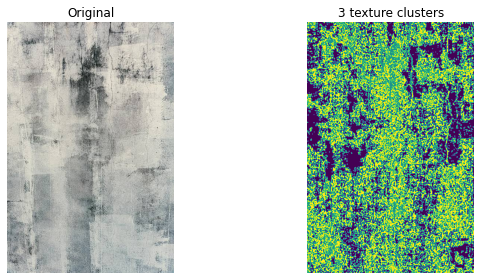

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import graycomatrix, graycoprops
from sklearn.cluster import KMeans

img = cv2.imread("textures.png")
if img is None:
    raise FileNotFoundError("Add an image named textures.png.")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
# Quantise grayscale to 8 levels to make local GLCM calculation efficient.
q = (gray // 32).astype(np.uint8)
pad = cv2.copyMakeBorder(q, 1, 1, 1, 1, cv2.BORDER_REFLECT)
features = np.zeros((gray.shape[0], gray.shape[1], 3), dtype=np.float32)

for y in range(gray.shape[0]):
    for x in range(gray.shape[1]):
        patch = pad[y:y+3, x:x+3]
        glcm = graycomatrix(patch, distances=[1], angles=[0], levels=8,
                            symmetric=True, normed=True)
        features[y, x, 0] = graycoprops(glcm, "contrast")[0, 0]
        features[y, x, 1] = graycoprops(glcm, "energy")[0, 0]
        features[y, x, 2] = graycoprops(glcm, "homogeneity")[0, 0]

X = features.reshape(-1, 3)
# Standardise each feature to prevent one scale dominating.
mu, sigma = X.mean(axis=0), X.std(axis=0)
X_scaled = (X - mu) / np.where(sigma == 0, 1, sigma)
labels = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X_scaled)
seg = labels.reshape(gray.shape)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); plt.title("Original"); plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(seg, cmap="viridis"); plt.title("3 texture clusters"); plt.axis("off")
plt.tight_layout(); plt.show()

**Explanation:** Each 3×3 neighbourhood gets three GLCM texture measurements. K-means groups pixels with similar feature values. This per-pixel implementation is computationally expensive for large images; test with a smaller image first.

## Program 6 — Multi-feature segmentation for disease-region detection

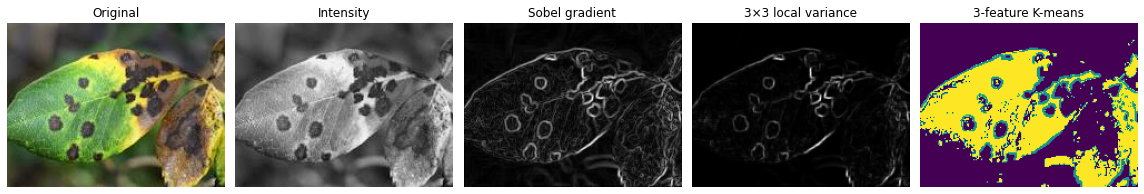

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

img = cv2.imread("leaf_disease.jpg")
if img is None:
    raise FileNotFoundError("Add a plant image named leaf_disease.jpg.")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
gradient = cv2.magnitude(gx, gy)
local_mean = cv2.blur(gray.astype(np.float32), (3, 3))
local_sq_mean = cv2.blur(gray.astype(np.float32) ** 2, (3, 3))
local_var = np.maximum(local_sq_mean - local_mean ** 2, 0)

def normalise(a):
    a = a.astype(np.float32)
    return (a - a.mean()) / (a.std() + 1e-6)

features = np.stack([normalise(gray), normalise(gradient), normalise(local_var)], axis=-1)
labels = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(features.reshape(-1, 3))
seg = labels.reshape(gray.shape)

fig, axes = plt.subplots(1, 5, figsize=(16, 4))
items = [(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), "Original"),
         (gray, "Intensity"), (gradient, "Sobel gradient"),
         (local_var, "3×3 local variance"), (seg, "3-feature K-means")]
for ax, (data, title) in zip(axes, items):
    ax.imshow(data, cmap=None if title == "Original" else "gray" if title != "3-feature K-means" else "viridis")
    ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

**Observation guide:** Intensity separates light/dark regions, gradient highlights boundaries, and local variance highlights local texture changes. K-means labels are arbitrary cluster IDs, so the cluster with the highest number is not automatically the diseased region. Without a labelled ground-truth mask, this is visual exploration rather than a measured disease-detection accuracy result.

## Program 7 — Morphological operations: erosion, dilation, opening, and closing

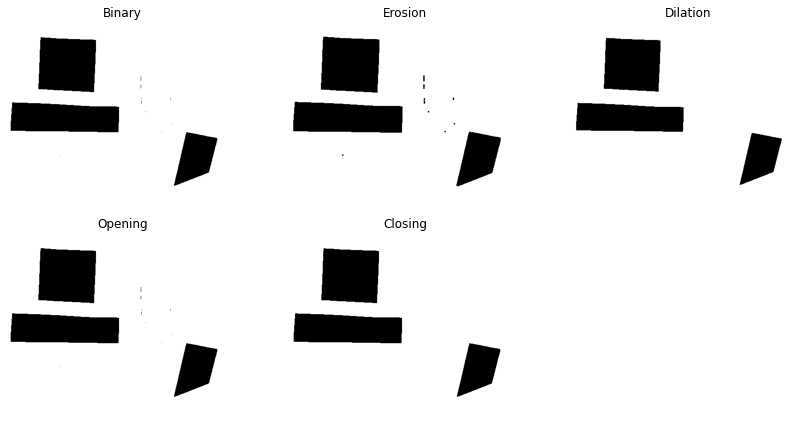

In [2]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread("shapes.png", cv2.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError("Add a grayscale image named shapes.png.")
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

erosion = cv2.erode(binary, kernel, iterations=1)
dilation = cv2.dilate(binary, kernel, iterations=1)
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

items = [("Binary", binary), ("Erosion", erosion), ("Dilation", dilation),
         ("Opening", opening), ("Closing", closing)]
plt.figure(figsize=(12, 6))
for i, (title, arr) in enumerate(items, 1):
    plt.subplot(2, 3, i); plt.imshow(arr, cmap="gray"); plt.title(title); plt.axis("off")
plt.tight_layout(); plt.show()

**Explanation:** Erosion shrinks foreground regions; dilation expands them. Opening (erosion then dilation) can remove small foreground specks, while closing (dilation then erosion) can fill small gaps.

## Program 8 — Detect contours, bounding boxes, and contour area

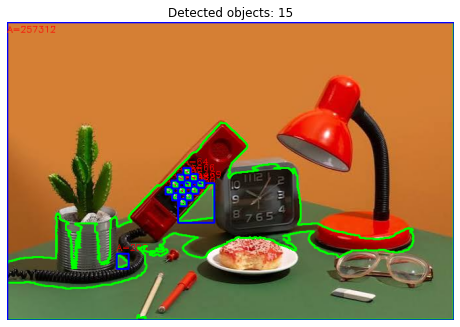

Objects retained after area filtering: 15


In [3]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread("objects.png")
if img is None:
    raise FileNotFoundError("Add an image named objects.png.")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray, (5, 5), 0)
_, binary = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

output = img.copy()
count = 0
for contour in contours:
    area = cv2.contourArea(contour)
    if area < 50:  # ignore tiny noise contours; adjust for your image
        continue
    x, y, w, h = cv2.boundingRect(contour)
    cv2.drawContours(output, [contour], -1, (0, 255, 0), 2)
    cv2.rectangle(output, (x, y), (x+w, y+h), (255, 0, 0), 2)
    cv2.putText(output, f"A={area:.0f}", (x, max(15, y-5)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 255), 1)
    count += 1

plt.figure(figsize=(8, 6))
plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.title(f"Detected objects: {count}")
plt.axis("off")
plt.show()
print("Objects retained after area filtering:", count)

**Explanation:** Contours trace object boundaries. Bounding rectangles provide simple object locations, and contour area estimates the number of pixels inside a boundary. Threshold polarity may need adjustment depending on whether objects are lighter or darker than the background.

## Program 9 — Improve contrast using histogram equalisation

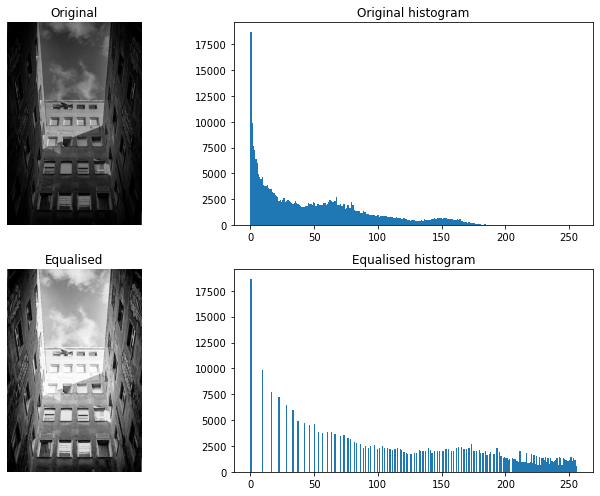

In [4]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread("low_contrast.jpg", cv2.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError("Add a grayscale image named low_contrast.jpg.")
enhanced = cv2.equalizeHist(img)

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
axes[0, 0].imshow(img, cmap="gray"); axes[0, 0].set_title("Original")
axes[0, 1].hist(img.ravel(), bins=256, range=(0, 256)); axes[0, 1].set_title("Original histogram")
axes[1, 0].imshow(enhanced, cmap="gray"); axes[1, 0].set_title("Equalised")
axes[1, 1].hist(enhanced.ravel(), bins=256, range=(0, 256)); axes[1, 1].set_title("Equalised histogram")
for ax in axes.flat:
    if hasattr(ax, "get_xaxis"): ax.set_axis_off() if ax in (axes[0,0], axes[1,0]) else None
plt.tight_layout(); plt.show()

**Explanation:** Histogram equalisation redistributes grayscale intensities to increase global contrast. It can also make noise more visible, so it is not ideal for every image.

## Program 10 — Compare Gaussian and median denoising using MSE and PSNR

Noisy    MSE=573.86, PSNR=20.54 dB
Gaussian MSE=126.32, PSNR=27.12 dB
Median   MSE=154.55, PSNR=26.24 dB


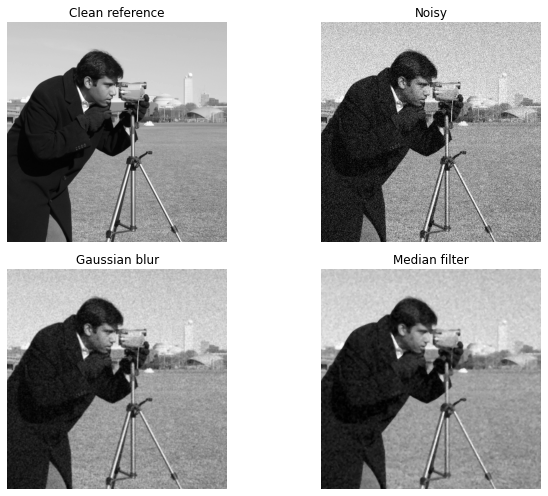

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

clean = cv2.imread("clean_image.jpg", cv2.IMREAD_GRAYSCALE)
noisy = cv2.imread("noisy_image.jpg", cv2.IMREAD_GRAYSCALE)
if clean is None or noisy is None:
    raise FileNotFoundError("Add both clean_image.jpg and noisy_image.jpg.")
if clean.shape != noisy.shape:
    raise ValueError("The clean and noisy images must have identical dimensions.")

gaussian = cv2.GaussianBlur(noisy, (5, 5), 0)
median = cv2.medianBlur(noisy, 5)

def metrics(reference, result):
    mse = np.mean((reference.astype(np.float64) - result.astype(np.float64)) ** 2)
    psnr = float("inf") if mse == 0 else 10 * np.log10(255**2 / mse)
    return mse, psnr

for name, result in [("Noisy", noisy), ("Gaussian", gaussian), ("Median", median)]:
    mse, psnr = metrics(clean, result)
    print(f"{name:8s} MSE={mse:.2f}, PSNR={psnr:.2f} dB")

items = [("Clean reference", clean), ("Noisy", noisy), ("Gaussian blur", gaussian), ("Median filter", median)]
plt.figure(figsize=(10, 7))
for i, (title, arr) in enumerate(items, 1):
    plt.subplot(2, 2, i); plt.imshow(arr, cmap="gray"); plt.title(title); plt.axis("off")
plt.tight_layout(); plt.show()

**Explanation:** MSE measures average squared pixel error; lower is better. PSNR expresses reconstruction quality in decibels; higher is generally better. Median filtering often handles impulse noise well, while Gaussian blur is a common choice for approximately Gaussian noise. Compare the actual metrics and visual details for your images.